In [1]:
# Install the libraries needed 

%pip install requests beautifulsoup4 pandas matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
#  Import the tools we need

import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt

# Print a message to confirm that the imports worked
print("All libraries are ready!")

All libraries are ready!


In [4]:
# Connect to the first page of the book website

url = "https://books.toscrape.com/catalogue/page-1.html"

# Send a request to the website
response = requests.get(url, timeout=15)

# Display the response status
print("Status code:", response.status_code)

Status code: 200


In [6]:
#Read and analyze the webpage HTML

soup = BeautifulSoup(response.text, "html.parser")

# Print the webpage title
print("Website title:", soup.title.get_text(strip=True))

# Find all the books listed on this page
books = soup.select("article.product_pod")

# Count how many books we found
print("Books found:", len(books))

Website title: All products | Books to Scrape - Sandbox
Books found: 20


In [7]:
# Select the first book on the page

book = books[0]

# Extract the book title
title = book.h3.a["title"]

# Extract the book price as text
price_text = book.select_one(".price_color").get_text(strip=True)

# Extract whether the book is in stock
availability = book.select_one(".availability").get_text(strip=True)

# Extract the book's star rating
rating = book.select_one(".star-rating")["class"][1]

# Print the information we collected
print("Title:", title)
print("Price:", price_text)
print("Availability:", availability)
print("Rating:", rating)

Title: A Light in the Attic
Price: Â£51.77
Availability: In stock
Rating: Three


In [8]:
# Create an empty list to store book information

book_data = []

# Go through every book found on the first page
for book in books:

    # Get the book title
    title = book.h3.a["title"]

    # Get the price as text
    price_text = book.select_one(".price_color").get_text(strip=True)

    # Convert the price from text into a number
    price = float(
        price_text.replace("Â", "").replace("£", "").strip()
    )

    # Get the stock availability
    availability = book.select_one(".availability").get_text(strip=True)

    # Get the star rating
    rating = book.select_one(".star-rating")["class"][1]

    # Save this book's information as a dictionary
    book_data.append({
        "title": title,
        "price_gbp": price,
        "availability": availability,
        "rating": rating
    })

# Turn the collected information into a table
df = pd.DataFrame(book_data)

# Show the first five rows
df.head()

,title,price_gbp,availability,rating
0,A Light in the Attic,51.77,In stock,Three
1,Tipping the Velvet,53.74,In stock,One
2,Soumission,50.10,In stock,One
3,Sharp Objects,47.82,In stock,Four
4,Sapiens: A Brief History of Humankind,54.23,In stock,Five


In [9]:
#Collect book information from five website pages

# Start with an empty list
book_data = []

# Website address: the page number will change each time
base_url = "https://books.toscrape.com/catalogue/page-{}.html"

# Visit pages 1, 2, 3, 4 and 5
for page in range(1, 6):

    # Create the URL for the current page
    url = base_url.format(page)

    # Request the webpage
    response = requests.get(url, timeout=15)

    # Stop if the website returns an error
    response.raise_for_status()

    # Read the webpage
    soup = BeautifulSoup(response.text, "html.parser")

    # Find all books on this page
    books = soup.select("article.product_pod")

    # Extract information from each book
    for book in books:

        # Get the title
        title = book.h3.a["title"]

        # Get the price and convert it into a number
        price_text = book.select_one(".price_color").get_text(strip=True)
        price = float(
            price_text.replace("Â", "").replace("£", "").strip()
        )

        # Get availability
        availability = book.select_one(".availability").get_text(strip=True)

        # Get the star rating
        rating = book.select_one(".star-rating")["class"][1]

        # Save the information
        book_data.append({
            "title": title,
            "price_gbp": price,
            "availability": availability,
            "rating": rating
        })

    # Tell us how many books were found on this page
    print(f"Page {page}: collected {len(books)} books")

# Convert all collected books into a DataFrame table
df = pd.DataFrame(book_data)

# Display the total number of books collected
print("Total books collected:", len(df))

# Display the first five rows
df.head()

Page 1: collected 20 books
Page 2: collected 20 books
Page 3: collected 20 books
Page 4: collected 20 books
Page 5: collected 20 books
Total books collected: 100


,title,price_gbp,availability,rating
0,A Light in the Attic,51.77,In stock,Three
1,Tipping the Velvet,53.74,In stock,One
2,Soumission,50.10,In stock,One
3,Sharp Objects,47.82,In stock,Four
4,Sapiens: A Brief History of Humankind,54.23,In stock,Five


In [10]:
#Check the quality of our collected data

# Show the number of rows and columns
print("Table size:", df.shape)

# Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Count duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Show basic statistics about book prices
print("\nPrice statistics:")
print(df["price_gbp"].describe())

Table size: (100, 4)

Missing values:
title           0
price_gbp       0
availability    0
rating          0
dtype: int64

Duplicate rows: 0

Price statistics:
count    100.000000
mean      34.560700
std       14.638531
min       10.160000
25%       19.897500
50%       34.775000
75%       47.967500
max       58.110000
Name: price_gbp, dtype: float64


In [11]:
#Save the collected books to a CSV file

df.to_csv("books.csv", index=False, encoding="utf-8-sig")

# Confirm that the command has run
print("Data saved successfully to books.csv")

Data saved successfully to books.csv


In [12]:
#Find the cheapest and most expensive books

# Find the row containing the lowest price
cheapest_book = df.loc[df["price_gbp"].idxmin()]

# Find the row containing the highest price
most_expensive_book = df.loc[df["price_gbp"].idxmax()]

# Calculate the average price
average_price = df["price_gbp"].mean()

# Display the results
print("Cheapest book:", cheapest_book["title"])
print("Cheapest price: £", round(cheapest_book["price_gbp"], 2))

print("\nMost expensive book:", most_expensive_book["title"])
print("Most expensive price: £", round(most_expensive_book["price_gbp"], 2))

print("\nAverage book price: £", round(average_price, 2))

Cheapest book: Patience
Cheapest price: £ 10.16

Most expensive book: The Death of Humanity: and the Case for Life
Most expensive price: £ 58.11

Average book price: £ 34.56


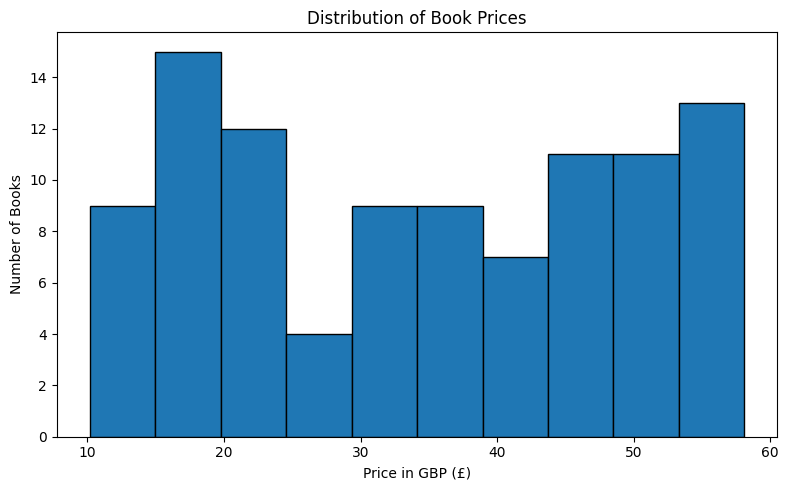

In [13]:
# Create a histogram of book prices

# Set the chart size
plt.figure(figsize=(8, 5))

# Create a histogram using the book prices
plt.hist(df["price_gbp"], bins=10, edgecolor="black")

# Add a chart title and labels
plt.title("Distribution of Book Prices")
plt.xlabel("Price in GBP (£)")
plt.ylabel("Number of Books")

# Make the chart easier to read
plt.tight_layout()

# Display the chart
plt.show()

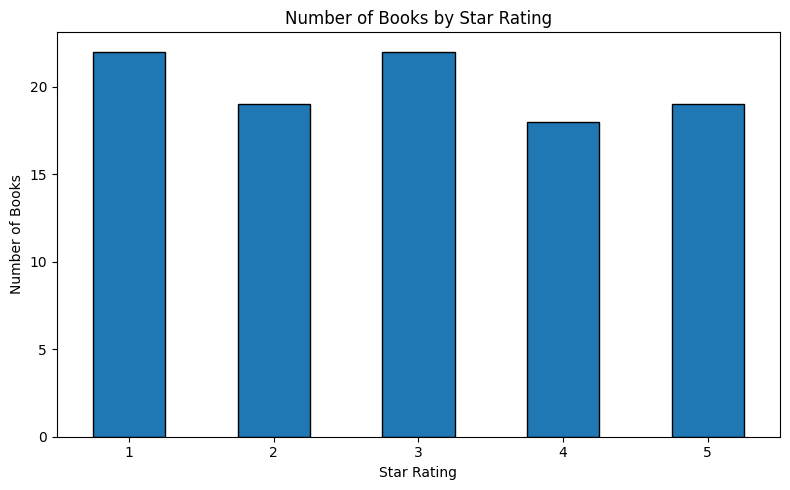

In [14]:
#Convert star ratings into numbers

# Create a dictionary to translate rating words into numbers
rating_numbers = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

# Create a new column containing numeric ratings
df["rating_number"] = df["rating"].map(rating_numbers)

# Count how many books have each rating
rating_counts = df["rating_number"].value_counts().sort_index()

# Create a bar chart
rating_counts.plot(kind="bar", figsize=(8, 5), edgecolor="black")

# Add a title and labels
plt.title("Number of Books by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")

# Show every rating from 1 to 5 on the horizontal axis
plt.xticks(rotation=0)

# Display the chart
plt.tight_layout()
plt.show()

In [15]:
#Display the final collected dataset

# Show the first 10 books
display(df.head(10))

# Show the total number of books
print("Total books:", len(df))

# Show all column names
print("Columns:", list(df.columns))

,title,price_gbp,availability,rating,rating_number
0,A Light in the Attic,51.77,In stock,Three,3
1,Tipping the Velvet,53.74,In stock,One,1
2,Soumission,50.10,In stock,One,1
3,Sharp Objects,47.82,In stock,Four,4
4,Sapiens: A Brief History of Humankind,54.23,In stock,Five,5
5,The Requiem Red,22.65,In stock,One,1
6,The Dirty Little Secrets of Getting Your Dream...,33.34,In stock,Four,4
7,The Coming Woman: A Novel Based on the Life of...,17.93,In stock,Three,3
8,The Boys in the Boat: Nine Americans and Their...,22.60,In stock,Four,4
9,The Black Maria,52.15,In stock,One,1


Total books: 100
Columns: ['title', 'price_gbp', 'availability', 'rating', 'rating_number']
